In [1]:
# Cell 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import ast

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Cell 2: Define data paths

processed_path = "../processed_data"
results_path = "../results"

print("Processed data directory:", os.path.abspath(processed_path))
print("Results directory:", os.path.abspath(results_path))

print("\nAvailable processed files:")

for file in os.listdir(processed_path):
    print("-", file)

Processed data directory: c:\Users\Shrutee Patil\Desktop\MSC Part 2 Sem 3\Research Project\Spotlight_project\processed_data
Results directory: c:\Users\Shrutee Patil\Desktop\MSC Part 2 Sem 3\Research Project\Spotlight_project\results

Available processed files:
- category_distribution.csv
- creator_popularity.csv
- interactions.csv
- testing_interactions.csv
- training_interactions.csv
- video_creator_groups.csv
- video_creator_map.csv
- video_metadata.csv


In [3]:
# Cell 3: Load datasets for interest modeling

training_data = pd.read_csv(
    os.path.join(processed_path, "training_interactions.csv")
)

video_metadata = pd.read_csv(
    os.path.join(processed_path, "video_metadata.csv")
)

print("Training data shape:", training_data.shape)
print("Video metadata shape:", video_metadata.shape)

print("\nTraining data columns:")
print(training_data.columns.tolist())

print("\nVideo metadata columns:")
print(video_metadata.columns.tolist())

Training data shape: (4387382, 9)
Video metadata shape: (3327, 12)

Training data columns:
['user_id', 'video_id', 'play_duration', 'video_duration', 'time', 'date', 'timestamp', 'watch_ratio', 'interaction_date']

Video metadata columns:
['video_id', 'category_ids', 'category_count', 'manual_cover_text', 'caption', 'topic_tag', 'first_level_category_id', 'first_level_category_name', 'second_level_category_id', 'second_level_category_name', 'third_level_category_id', 'third_level_category_name']


In [4]:
# Cell 4: Inspect video category representation

print("Category IDs data type:")
print(video_metadata["category_ids"].dtype)

print("\nSample category values:")
display(
    video_metadata[
        ["video_id", "category_ids", "category_count"]
    ].head(15)
)

print("\nCategory count distribution:")
print(video_metadata["category_count"].value_counts().sort_index())

Category IDs data type:
object

Sample category values:


,video_id,category_ids,category_count
0,103,[12],1
1,109,"[18, 5]",2
2,120,[9],1
3,122,[9],1
4,128,"[11, 12, 9]",3
5,130,"[15, 20]",2
6,131,"[9, 28]",2
7,133,[17],1
8,136,"[11, 28]",2
9,137,[28],1



Category count distribution:
category_count
1    2209
2     973
3     138
4       7
Name: count, dtype: int64


In [5]:
# Cell 5: Parse category IDs

video_metadata["category_ids"] = video_metadata["category_ids"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

print("Category IDs parsed successfully!")

print("\nSample parsed categories:")
display(
    video_metadata[
        ["video_id", "category_ids", "category_count"]
    ].head(10)
)

print("\nData type after parsing:")
print(type(video_metadata["category_ids"].iloc[0]))

Category IDs parsed successfully!

Sample parsed categories:


,video_id,category_ids,category_count
0,103,[12],1
1,109,"[18, 5]",2
2,120,[9],1
3,122,[9],1
4,128,"[11, 12, 9]",3
5,130,"[15, 20]",2
6,131,"[9, 28]",2
7,133,[17],1
8,136,"[11, 28]",2
9,137,[28],1



Data type after parsing:
<class 'list'>


In [6]:
# Cell 6: Validate category metadata

# Check whether every category_ids entry is a list
all_lists = video_metadata["category_ids"].apply(lambda x: isinstance(x, list)).all()

# Check for empty category lists
empty_categories = video_metadata["category_ids"].apply(lambda x: len(x) == 0).sum()

# Check whether category IDs are numerical
valid_category_ids = video_metadata["category_ids"].apply(
    lambda x: all(isinstance(cat, (int, float)) for cat in x)
).all()

# Check consistency between category_count and actual list length
count_mismatches = (
    video_metadata["category_count"] !=
    video_metadata["category_ids"].apply(len)
).sum()

print("All category entries are lists:", all_lists)
print("Videos with empty category lists:", empty_categories)
print("All category IDs are numerical:", valid_category_ids)
print("Category count mismatches:", count_mismatches)

All category entries are lists: True
Videos with empty category lists: 0
All category IDs are numerical: True
Category count mismatches: 0


In [7]:
# Cell 7: Analyse category distribution

# Expand multi-label categories into individual rows
exploded_categories = video_metadata[["video_id", "category_ids"]].explode("category_ids")

# Calculate the number of videos associated with each category
category_video_counts = (
    exploded_categories.groupby("category_ids")["video_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index()
)

category_video_counts.columns = ["category_id", "video_count"]

# Calculate percentage of videos assigned to each category
category_video_counts["percentage"] = (
    category_video_counts["video_count"] / len(video_metadata) * 100
)

print("Number of unique categories:", category_video_counts["category_id"].nunique())
print("\nCategory distribution:")
display(category_video_counts)

Number of unique categories: 31

Category distribution:


,category_id,video_count,percentage
0,28,849,25.518485
1,8,506,15.208897
2,6,451,13.555756
3,11,426,12.804328
4,9,332,9.978960
5,26,330,9.918846
6,7,208,6.251879
7,17,189,5.680794
8,1,163,4.899309
9,25,161,4.839194


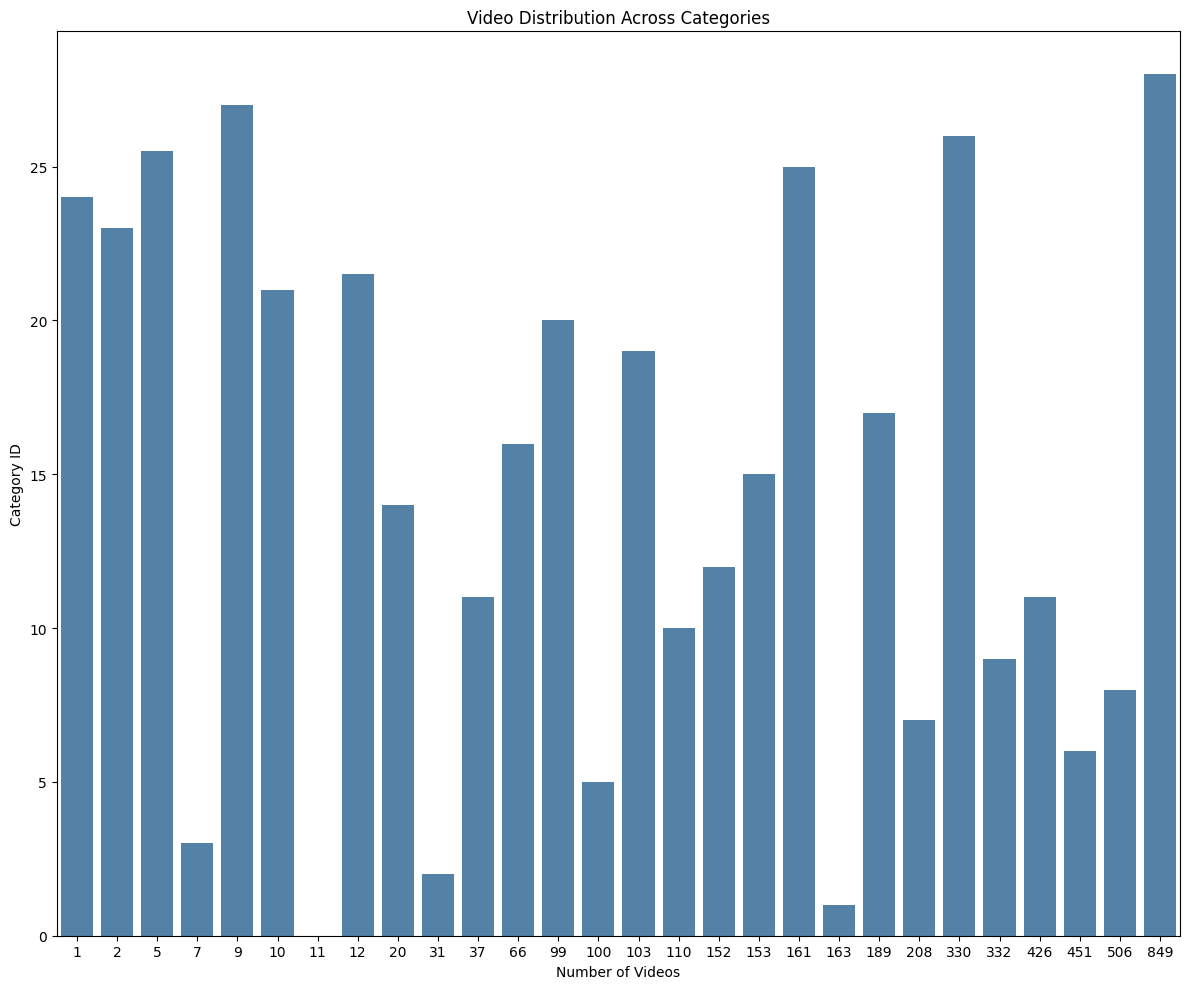

In [9]:
# Cell 8: Visualise category distribution

plt.figure(figsize=(12, 10))

sns.barplot(
    data=category_video_counts,
    x="video_count",
    y="category_id",
    color="steelblue",
    errorbar=None
)

plt.title("Video Distribution Across Categories")
plt.xlabel("Number of Videos")
plt.ylabel("Category ID")
plt.tight_layout()
plt.show()

In [10]:
# Cell 9: Prepare training interactions for interest modelling

interest_interactions = training_data[
    ["user_id", "video_id", "watch_ratio"]
].copy()

# Cap watch ratio between 0 and 1
interest_interactions["preference_score"] = (
    interest_interactions["watch_ratio"].clip(0, 1)
)

print("Interest interaction dataset shape:", interest_interactions.shape)
print("\nSample:")
display(interest_interactions.head())

print("\nPreference score statistics:")
display(interest_interactions["preference_score"].describe())

Interest interaction dataset shape: (4387382, 4)

Sample:


,user_id,video_id,watch_ratio,preference_score
0,14,148,0.722103,0.722103
1,14,183,1.907377,1.000000
2,14,3649,2.063311,1.000000
3,14,5262,0.566388,0.566388
4,14,8234,0.418364,0.418364



Preference score statistics:


count    4.387382e+06
mean     6.995833e-01
std      3.075442e-01
min      0.000000e+00
25%      4.735927e-01
50%      7.742437e-01
75%      1.000000e+00
max      1.000000e+00
Name: preference_score, dtype: float64

In [11]:
# Cell 10: Merge interaction data with video category metadata

interest_data = interest_interactions.merge(
    video_metadata[["video_id", "category_ids", "category_count"]],
    on="video_id",
    how="left",
    validate="many_to_one"
)

print("Merged interest dataset shape:", interest_data.shape)

# Check missing category metadata
missing_categories = interest_data["category_ids"].isna().sum()

print("Interactions missing category metadata:", missing_categories)
print("Percentage missing:", round(missing_categories / len(interest_data) * 100, 4), "%")

print("\nSample merged data:")
display(interest_data.head())

Merged interest dataset shape: (4387382, 6)
Interactions missing category metadata: 0
Percentage missing: 0.0 %

Sample merged data:


,user_id,video_id,watch_ratio,preference_score,category_ids,category_count
0,14,148,0.722103,0.722103,"[11, 28, 19]",3
1,14,183,1.907377,1.000000,[28],1
2,14,3649,2.063311,1.000000,[9],1
3,14,5262,0.566388,0.566388,[25],1
4,14,8234,0.418364,0.418364,[6],1


In [12]:
# Cell 11: Distribute preference scores across video categories

# Expand each video into separate category rows
user_category_interactions = interest_data.explode("category_ids").copy()

# Allocate preference equally across all assigned categories
user_category_interactions["category_contribution"] = (
    user_category_interactions["preference_score"] /
    user_category_interactions["category_count"]
)

print("Expanded dataset shape:", user_category_interactions.shape)

print("\nSample category-level interactions:")
display(
    user_category_interactions[
        ["user_id", "video_id", "category_ids",
         "preference_score", "category_count", "category_contribution"]
    ].head(10)
)

Expanded dataset shape: (6063117, 7)

Sample category-level interactions:


,user_id,video_id,category_ids,preference_score,category_count,category_contribution
0,14,148,11,0.722103,3,0.240701
0,14,148,28,0.722103,3,0.240701
0,14,148,19,0.722103,3,0.240701
1,14,183,28,1.000000,1,1.000000
2,14,3649,9,1.000000,1,1.000000
3,14,5262,25,0.566388,1,0.566388
4,14,8234,6,0.418364,1,0.418364
5,14,6789,1,0.648753,1,0.648753
6,14,1963,9,0.898123,2,0.449062
6,14,1963,28,0.898123,2,0.449062


In [13]:
# Cell 12: Aggregate user-category interest

user_category_interest = (
    user_category_interactions
    .groupby(["user_id", "category_ids"])["category_contribution"]
    .sum()
    .reset_index()
)

user_category_interest.rename(
    columns={
        "category_ids": "category_id",
        "category_contribution": "interest_score"
    },
    inplace=True
)

print("User-category interest dataset shape:", user_category_interest.shape)

print("\nSample user-category interest scores:")
display(user_category_interest.head(15))

User-category interest dataset shape: (43707, 3)

Sample user-category interest scores:


,user_id,category_id,interest_score
0,14,0,3.714641
1,14,1,87.236019
2,14,2,11.490888
3,14,3,1.635982
4,14,4,20.575255
5,14,5,50.118058
6,14,6,219.677215
7,14,7,138.418552
8,14,8,259.857319
9,14,9,131.379608


In [14]:
# Cell 13: Normalize user-category interest scores

user_category_interest["interest_weight"] = (
    user_category_interest["interest_score"] /
    user_category_interest.groupby("user_id")["interest_score"].transform("sum")
)

print("Normalized user-category profiles created!")

# Verify profile sums
profile_sums = (
    user_category_interest.groupby("user_id")["interest_weight"].sum()
)

print("\nProfile sum statistics:")
display(profile_sums.describe())

print("\nNumber of users:", profile_sums.shape[0])
print("Profiles not summing to 1:", 
      ((profile_sums - 1).abs() > 1e-6).sum())

print("\nSample normalized profile for User 14:")
display(
    user_category_interest[
        user_category_interest["user_id"] == 14
    ].sort_values("interest_weight", ascending=False)
)

Normalized user-category profiles created!

Profile sum statistics:


count    1.411000e+03
mean     1.000000e+00
std      5.687240e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: interest_weight, dtype: float64


Number of users: 1411
Profiles not summing to 1: 0

Sample normalized profile for User 14:


,user_id,category_id,interest_score,interest_weight
28,14,28,507.978342,0.218828
8,14,8,259.857319,0.111942
6,14,6,219.677215,0.094633
11,14,11,191.827600,0.082636
26,14,26,146.794535,0.063237
7,14,7,138.418552,0.059628
9,14,9,131.379608,0.056596
17,14,17,111.912526,0.048210
1,14,1,87.236019,0.037580
15,14,15,85.435851,0.036804


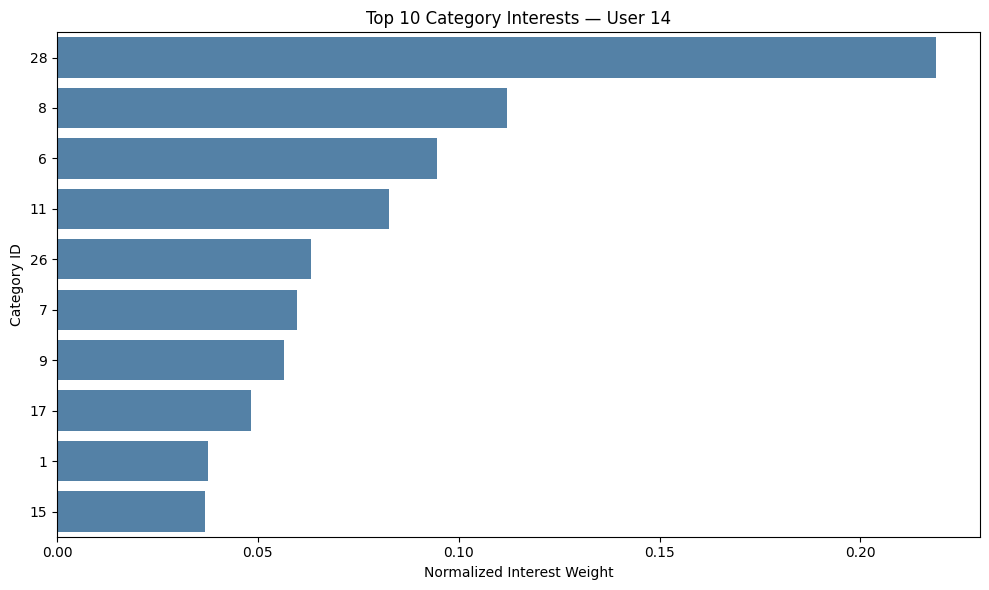

In [16]:
# Cell 14: Visualise an individual user interest profile

sample_user_id = 14

sample_profile = (
    user_category_interest[
        user_category_interest["user_id"] == sample_user_id
    ]
    .sort_values("interest_weight", ascending=False)
    .head(10)
    .copy()
)

# Convert category IDs to categorical labels for plotting
sample_profile["category_id"] = sample_profile["category_id"].astype(str)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=sample_profile,
    x="interest_weight",
    y="category_id",
    orient="h",
    color="steelblue",
    errorbar=None
)

plt.title(f"Top 10 Category Interests — User {sample_user_id}")
plt.xlabel("Normalized Interest Weight")
plt.ylabel("Category ID")
plt.tight_layout()
plt.show()

In [17]:
# Cell 15: Analyse interest profiles across the user population

# Number of categories represented in each user's profile
user_category_counts = (
    user_category_interest.groupby("user_id")["category_id"]
    .nunique()
)

# Average normalized interest assigned to each category across users
category_average_interest = (
    user_category_interest.groupby("category_id")["interest_weight"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

print("User category profile statistics:")
display(user_category_counts.describe())

print("\nAverage number of categories per user:", 
      round(user_category_counts.mean(), 2))

print("\nCategory average interest across users:")
display(category_average_interest)

print("\nTotal users analysed:", user_category_counts.nunique() * 0 + user_category_counts.shape[0])

User category profile statistics:


count    1411.000000
mean       30.975904
std         0.153403
min        30.000000
25%        31.000000
50%        31.000000
75%        31.000000
max        31.000000
Name: category_id, dtype: float64


Average number of categories per user: 30.98

Category average interest across users:


,category_id,interest_weight
0,28,0.218294
1,8,0.113804
2,6,0.091596
3,11,0.082883
4,26,0.065624
5,7,0.060467
6,9,0.054629
7,17,0.047251
8,15,0.038196
9,1,0.037994



Total users analysed: 1411


In [18]:
# Cell 16: Measure interest concentration across users

def calculate_profile_metrics(profile):
    weights = profile["interest_weight"].values

    # Top 3 category interest share
    top_3_share = np.sort(weights)[-3:].sum()

    # Shannon entropy
    entropy = -np.sum(weights * np.log(weights + 1e-12))

    # Effective number of categories
    effective_categories = np.exp(entropy)

    return pd.Series({
        "top_3_interest_share": top_3_share,
        "interest_entropy": entropy,
        "effective_categories": effective_categories
    })


user_interest_metrics = (
    user_category_interest
    .groupby("user_id")
    .apply(calculate_profile_metrics)
    .reset_index()
)

print("User interest concentration metrics:")
display(user_interest_metrics.head())

print("\nSummary statistics:")
display(user_interest_metrics.drop(columns="user_id").describe())

User interest concentration metrics:


C:\Users\Shrutee Patil\AppData\Local\Temp\ipykernel_7100\1422745158.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_profile_metrics)


,user_id,top_3_interest_share,interest_entropy,effective_categories
0,14,0.425404,2.682197,14.617169
1,19,0.422860,2.679368,14.575873
2,21,0.416175,2.694675,14.800711
3,23,0.415169,2.685570,14.666565
4,24,0.428517,2.676274,14.530855



Summary statistics:


,top_3_interest_share,interest_entropy,effective_categories
count,1411.000000,1411.000000,1411.000000
mean,0.423762,2.683327,14.634599
std,0.005279,0.011131,0.162973
min,0.402385,2.647527,14.119080
25%,0.420287,2.675695,14.522435
50%,0.423962,2.683542,14.636852
75%,0.427096,2.690440,14.738155
max,0.441994,2.725150,15.258703


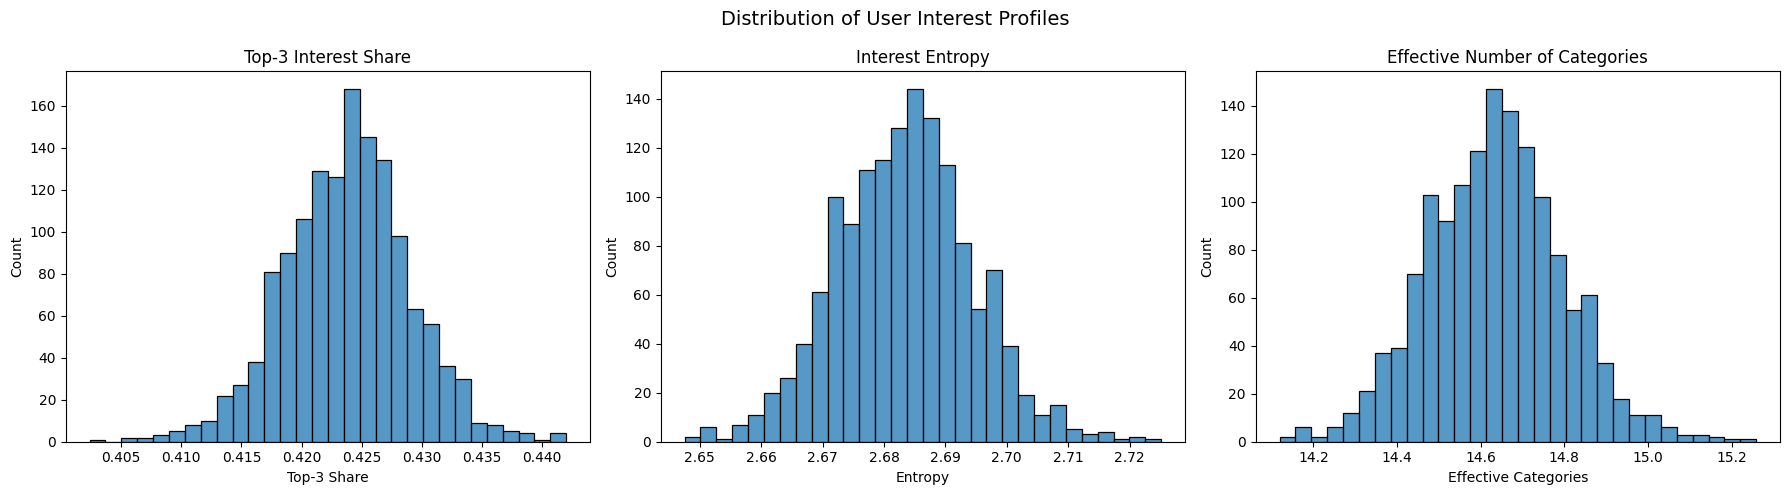

In [19]:
# Cell 17: Visualise user interest concentration metrics

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    user_interest_metrics["top_3_interest_share"],
    bins=30,
    ax=axes[0]
)
axes[0].set_title("Top-3 Interest Share")
axes[0].set_xlabel("Top-3 Share")

sns.histplot(
    user_interest_metrics["interest_entropy"],
    bins=30,
    ax=axes[1]
)
axes[1].set_title("Interest Entropy")
axes[1].set_xlabel("Entropy")

sns.histplot(
    user_interest_metrics["effective_categories"],
    bins=30,
    ax=axes[2]
)
axes[2].set_title("Effective Number of Categories")
axes[2].set_xlabel("Effective Categories")

plt.suptitle("Distribution of User Interest Profiles", fontsize=14)
plt.tight_layout()
plt.show()

In [20]:
# Cell 18: Compare individual profiles with the global interest profile

# Create user-category matrix
user_interest_matrix = user_category_interest.pivot(
    index="user_id",
    columns="category_id",
    values="interest_weight"
).fillna(0)

# Average category-interest profile across users
global_interest_profile = user_interest_matrix.mean(axis=0)

# Calculate cosine similarity between each user and the global profile
user_global_similarity = user_interest_matrix.apply(
    lambda row: np.dot(row, global_interest_profile) /
    (np.linalg.norm(row) * np.linalg.norm(global_interest_profile)),
    axis=1
)

print("User-global profile cosine similarity:")
display(user_global_similarity.describe())

print("\nMean similarity to global profile:",
      round(user_global_similarity.mean(), 6))

print("\nUsers with lowest similarity to global profile:")
display(user_global_similarity.sort_values().head(10))

print("\nUsers with highest similarity to global profile:")
display(user_global_similarity.sort_values(ascending=False).head(10))

User-global profile cosine similarity:


count    1411.000000
mean        0.999489
std         0.000462
min         0.995519
25%         0.999334
50%         0.999625
75%         0.999797
max         0.999962
dtype: float64


Mean similarity to global profile: 0.999489

Users with lowest similarity to global profile:


user_id
5893    0.995519
1457    0.995775
4479    0.996596
6111    0.996893
7056    0.996941
23      0.997002
2108    0.997226
1257    0.997399
1029    0.997446
5552    0.997467
dtype: float64


Users with highest similarity to global profile:


user_id
1653    0.999962
4678    0.999960
2205    0.999959
3464    0.999956
2005    0.999955
3789    0.999953
6122    0.999950
3404    0.999947
5158    0.999947
5342    0.999945
dtype: float64

In [21]:
# Cell 19: Measure category-level variation across users

category_profile_variation = (
    user_interest_matrix.std(axis=0)
    .sort_values(ascending=False)
    .reset_index()
)

category_profile_variation.columns = [
    "category_id",
    "interest_weight_std"
]

print("Categories with the greatest variation across users:")
display(category_profile_variation.head(15))

print("\nCategories with the least variation across users:")
display(category_profile_variation.tail(10))

print("\nOverall category variation:")
display(category_profile_variation["interest_weight_std"].describe())

Categories with the greatest variation across users:


,category_id,interest_weight_std
0,28,0.006071
1,8,0.003518
2,6,0.003492
3,7,0.002302
4,9,0.002275
5,26,0.002168
6,15,0.002149
7,11,0.002118
8,17,0.002115
9,12,0.002113



Categories with the least variation across users:


,category_id,interest_weight_std
21,21,0.000323
22,30,0.000281
23,13,0.000242
24,0,0.000229
25,3,0.000222
26,27,0.000199
27,29,0.000152
28,22,0.000119
29,23,0.000078
30,24,0.000061



Overall category variation:


count    31.000000
mean      0.001333
std       0.001326
min       0.000061
25%       0.000262
50%       0.001092
75%       0.002117
max       0.006071
Name: interest_weight_std, dtype: float64

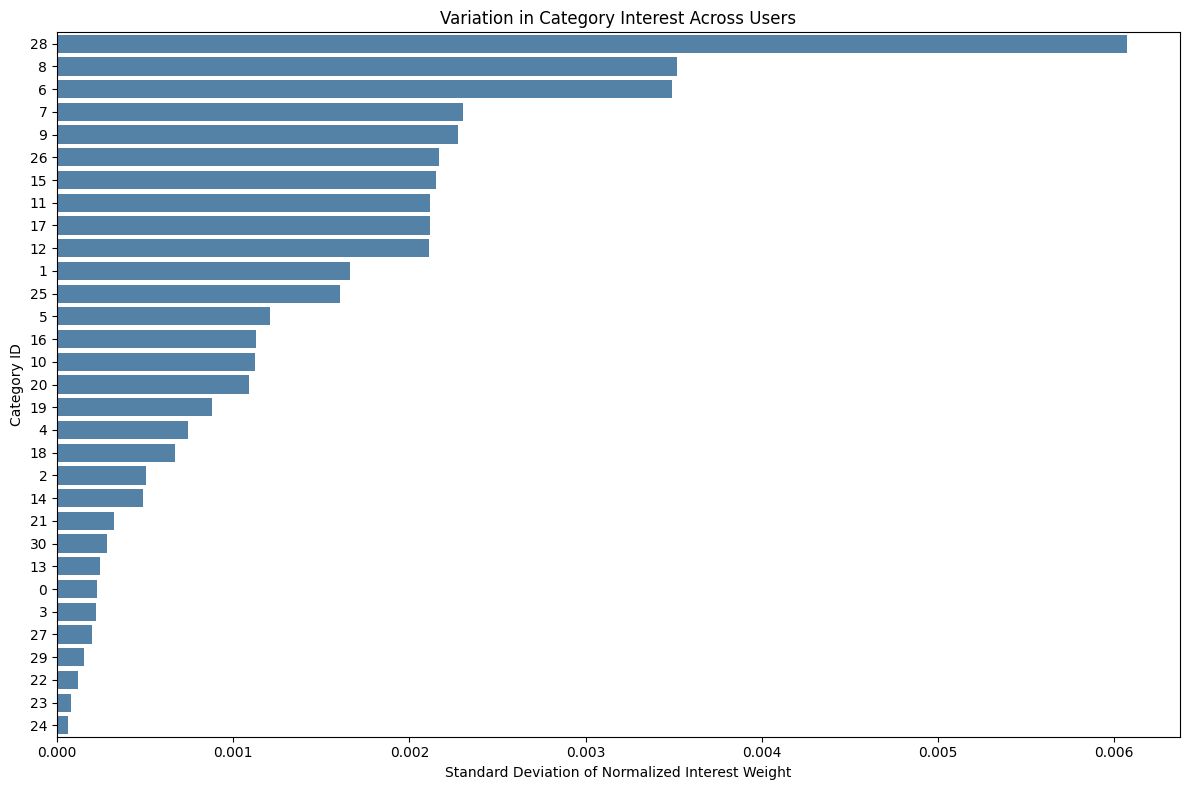

In [22]:
# Cell 20: Visualise category-level variation across users

variation_plot = category_profile_variation.copy()
variation_plot["category_id"] = variation_plot["category_id"].astype(str)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=variation_plot,
    x="interest_weight_std",
    y="category_id",
    color="steelblue",
    errorbar=None
)

plt.title("Variation in Category Interest Across Users")
plt.xlabel("Standard Deviation of Normalized Interest Weight")
plt.ylabel("Category ID")
plt.tight_layout()
plt.show()

In [23]:
# Cell 21: Analyse dominant categories across users

# Identify each user's highest-interest category
user_top_category = (
    user_category_interest
    .sort_values(
        ["user_id", "interest_weight"],
        ascending=[True, False]
    )
    .groupby("user_id")
    .first()
    .reset_index()
)

# Count how often each category is the dominant interest
dominant_category_distribution = (
    user_top_category["category_id"]
    .value_counts()
    .rename_axis("category_id")
    .reset_index(name="user_count")
)

dominant_category_distribution["percentage"] = (
    dominant_category_distribution["user_count"] /
    len(user_top_category) * 100
)

dominant_category_distribution = dominant_category_distribution.sort_values(
    "user_count", ascending=False
)

print("Number of users analysed:", len(user_top_category))

print("\nDominant category distribution:")
display(dominant_category_distribution)

print("\nMost common dominant category:")
display(dominant_category_distribution.head(10))

print("\nNumber of categories represented as users' dominant interest:",
      dominant_category_distribution["category_id"].nunique())

Number of users analysed: 1411

Dominant category distribution:


,category_id,user_count,percentage
0,28,1411,100.0



Most common dominant category:


,category_id,user_count,percentage
0,28,1411,100.0



Number of categories represented as users' dominant interest: 1


In [26]:
# Cell 22A: Safely inspect loaded notebook variables

current_variables = list(globals().keys())

print("expanded_interest_data exists:",
      "expanded_interest_data" in current_variables)

print("\nAvailable interest-related variables:")
for variable in current_variables:
    if "interest" in variable.lower() or "category" in variable.lower():
        print(variable)

expanded_interest_data exists: False

Available interest-related variables:
valid_category_ids
category_video_counts
interest_interactions
interest_data
user_category_interactions
user_category_interest
user_category_counts
category_average_interest
user_interest_metrics
user_interest_matrix
global_interest_profile
category_profile_variation
user_top_category
dominant_category_distribution


In [27]:
# Cell 22B: Inspect existing interest-related datasets

datasets_to_check = [
    "interest_data",
    "interest_interactions",
    "user_category_interactions"
]

for dataset_name in datasets_to_check:
    dataset = globals()[dataset_name]

    print(f"\n{'=' * 50}")
    print(f"Dataset: {dataset_name}")
    print("Shape:", dataset.shape)
    print("Columns:", dataset.columns.tolist())
    display(dataset.head(3))


Dataset: interest_data
Shape: (4387382, 6)
Columns: ['user_id', 'video_id', 'watch_ratio', 'preference_score', 'category_ids', 'category_count']


,user_id,video_id,watch_ratio,preference_score,category_ids,category_count
0,14,148,0.722103,0.722103,"[11, 28, 19]",3
1,14,183,1.907377,1.000000,[28],1
2,14,3649,2.063311,1.000000,[9],1



Dataset: interest_interactions
Shape: (4387382, 4)
Columns: ['user_id', 'video_id', 'watch_ratio', 'preference_score']


,user_id,video_id,watch_ratio,preference_score
0,14,148,0.722103,0.722103
1,14,183,1.907377,1.000000
2,14,3649,2.063311,1.000000



Dataset: user_category_interactions
Shape: (6063117, 7)
Columns: ['user_id', 'video_id', 'watch_ratio', 'preference_score', 'category_ids', 'category_count', 'category_contribution']


,user_id,video_id,watch_ratio,preference_score,category_ids,category_count,category_contribution
0,14,148,0.722103,0.722103,11,3,0.240701
0,14,148,0.722103,0.722103,28,3,0.240701
0,14,148,0.722103,0.722103,19,3,0.240701


In [28]:
# Cell 22: Calculate category interests using mean preference

user_category_mean_preference = (
    user_category_interactions
    .groupby(["user_id", "category_ids"])["preference_score"]
    .mean()
    .reset_index(name="mean_category_preference")
)

# Normalize category preferences within each user
user_category_mean_preference["interest_weight"] = (
    user_category_mean_preference
    .groupby("user_id")["mean_category_preference"]
    .transform(lambda x: x / x.sum())
)

print("Mean-preference interest dataset shape:",
      user_category_mean_preference.shape)

print("\nSample:")
display(user_category_mean_preference.head(10))

print("\nNormalized profile sum validation:")
profile_sums = (
    user_category_mean_preference
    .groupby("user_id")["interest_weight"]
    .sum()
)

display(profile_sums.describe())

print("\nProfiles not summing to 1:",
      (np.abs(profile_sums - 1) > 1e-6).sum())

Mean-preference interest dataset shape: (43707, 4)

Sample:


,user_id,category_ids,mean_category_preference,interest_weight
0,14,0,0.701592,0.032793
1,14,1,0.763993,0.035709
2,14,2,0.620291,0.028993
3,14,3,0.553769,0.025883
4,14,4,0.735436,0.034375
5,14,5,0.767601,0.035878
6,14,6,0.656392,0.030680
7,14,7,0.814710,0.038080
8,14,8,0.757394,0.035401
9,14,9,0.725393,0.033905



Normalized profile sum validation:


count    1.411000e+03
mean     1.000000e+00
std      1.467347e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: interest_weight, dtype: float64


Profiles not summing to 1: 0


In [29]:
# Cell 23: Analyse dominant categories using mean preference

user_mean_top_category = (
    user_category_mean_preference
    .sort_values(
        ["user_id", "interest_weight"],
        ascending=[True, False]
    )
    .groupby("user_id")
    .first()
    .reset_index()
)

mean_dominant_category_distribution = (
    user_mean_top_category["category_ids"]
    .value_counts()
    .rename_axis("category_id")
    .reset_index(name="user_count")
)

mean_dominant_category_distribution["percentage"] = (
    mean_dominant_category_distribution["user_count"]
    / len(user_mean_top_category) * 100
)

print("Users analysed:", len(user_mean_top_category))

print("\nDominant category distribution (mean preference):")
display(mean_dominant_category_distribution)

print("\nNumber of distinct dominant categories:",
      mean_dominant_category_distribution["category_id"].nunique())

Users analysed: 1411

Dominant category distribution (mean preference):


,category_id,user_count,percentage
0,24,1001,70.942594
1,23,90,6.378455
2,13,74,5.244507
3,28,66,4.677534
4,18,65,4.606662
5,29,24,1.700921
6,14,18,1.275691
7,5,15,1.063076
8,7,12,0.850461
9,3,11,0.779589



Number of distinct dominant categories: 18


In [31]:
# Cell 24: Investigate Category 24 dominance

# Calculate catalogue video counts by category
catalogue_category_counts = (
    video_metadata
    .explode("category_ids")
    .groupby("category_ids")["video_id"]
    .nunique()
    .reset_index(name="catalogue_video_count")
)

# Calculate interaction-level category statistics
category_diagnostics = (
    user_category_interactions
    .groupby("category_ids")
    .agg(
        interaction_count=("user_id", "size"),
        unique_users=("user_id", "nunique"),
        unique_videos=("video_id", "nunique"),
        mean_preference=("preference_score", "mean"),
        mean_category_contribution=("category_contribution", "mean")
    )
    .reset_index()
)

# Merge catalogue availability
category_diagnostics = category_diagnostics.merge(
    catalogue_category_counts,
    on="category_ids",
    how="left"
)

category_diagnostics = category_diagnostics.sort_values(
    "unique_users",
    ascending=False
).reset_index(drop=True)

# Inspect Category 24 specifically
print("Category 24 diagnostics:")
display(
    category_diagnostics[
        category_diagnostics["category_ids"] == 24
    ]
)

# Compare Category 24 with the 10 most widely interacted categories
print("\nTop 10 categories by unique users:")
display(category_diagnostics.head(10))

Category 24 diagnostics:


,category_ids,interaction_count,unique_users,unique_videos,mean_preference,mean_category_contribution,catalogue_video_count
30,24,1380,1380,1,0.861852,0.430926,1



Top 10 categories by unique users:


,category_ids,interaction_count,unique_users,unique_videos,mean_preference,mean_category_contribution,catalogue_video_count
0,0,13371,1411,11,0.637114,0.323839,11
1,1,219993,1411,163,0.725535,0.530529,163
2,2,40820,1411,31,0.634689,0.399357,31
3,3,8752,1411,7,0.504540,0.390552,7
4,4,48661,1411,37,0.722416,0.585482,37
5,5,134460,1411,100,0.748691,0.501755,100
6,6,594214,1411,447,0.611161,0.473407,451
7,7,279070,1411,207,0.762003,0.664853,208
8,8,688967,1411,505,0.725073,0.507203,506
9,9,431835,1411,327,0.684289,0.388159,332


In [32]:
# Cell 25: Inspect the video associated with Category 24

category_24_video_ids = (
    user_category_interactions.loc[
        user_category_interactions["category_ids"] == 24,
        "video_id"
    ]
    .unique()
)

print("Videos assigned to Category 24:", category_24_video_ids)

# Inspect metadata for the video
category_24_metadata = video_metadata[
    video_metadata["video_id"].isin(category_24_video_ids)
]

display(category_24_metadata)

# Inspect interaction behaviour for this video
category_24_interactions = training_interactions[
    training_interactions["video_id"].isin(category_24_video_ids)
]

print("\nCategory 24 video interaction statistics:")
print("Total interactions:", len(category_24_interactions))
print("Unique users:", category_24_interactions["user_id"].nunique())

display(
    category_24_interactions["watch_ratio"].describe()
)


Videos assigned to Category 24: [4359]


,video_id,category_ids,category_count,manual_cover_text,caption,topic_tag,first_level_category_id,first_level_category_name,second_level_category_id,second_level_category_name,third_level_category_id,third_level_category_name
1554,4359,"[24, 11]",2,ing情侣头像,🌝,[],19.0,情感,744.0,情感关系,-124.0,UNKNOWN


NameError: name 'training_interactions' is not defined

In [33]:
# Inspect interaction behaviour using interest_data

category_24_interactions = interest_data[
    interest_data["video_id"].isin(category_24_video_ids)
]

print("\nCategory 24 video interaction statistics:")
print("Total interactions:", len(category_24_interactions))
print("Unique users:", category_24_interactions["user_id"].nunique())

print("\nWatch ratio statistics:")
display(category_24_interactions["watch_ratio"].describe())

print("\nPreference score statistics:")
display(category_24_interactions["preference_score"].describe())


Category 24 video interaction statistics:
Total interactions: 1380
Unique users: 1380

Watch ratio statistics:


count    1380.000000
mean        1.162964
std         1.163380
min         0.000000
25%         0.808865
50%         1.077321
75%         1.371470
max        34.667226
Name: watch_ratio, dtype: float64


Preference score statistics:


count    1380.000000
mean        0.861852
std         0.235385
min         0.000000
25%         0.808865
50%         1.000000
75%         1.000000
max         1.000000
Name: preference_score, dtype: float64

In [34]:
# Cell 26: Reliability-adjusted category interest

# Calculate user-category preference and support
user_category_reliability = (
    user_category_interactions
    .groupby(["user_id", "category_ids"])
    .agg(
        mean_user_preference=("preference_score", "mean"),
        unique_videos=("video_id", "nunique")
    )
    .reset_index()
)

# Calculate category-level prior
category_prior = (
    user_category_reliability
    .groupby("category_ids")["mean_user_preference"]
    .mean()
    .reset_index(name="category_prior")
)

# Merge category prior
user_category_reliability = user_category_reliability.merge(
    category_prior,
    on="category_ids",
    how="left"
)

# Smoothing parameter
m = 5

# Reliability-adjusted preference
user_category_reliability["adjusted_interest"] = (
    (
        user_category_reliability["unique_videos"]
        / (user_category_reliability["unique_videos"] + m)
    )
    * user_category_reliability["mean_user_preference"]
    +
    (
        m
        / (user_category_reliability["unique_videos"] + m)
    )
    * user_category_reliability["category_prior"]
)

# Normalize scores within each user
user_category_reliability["interest_weight"] = (
    user_category_reliability
    .groupby("user_id")["adjusted_interest"]
    .transform(lambda x: x / x.sum())
)

print("Reliability-adjusted profile shape:",
      user_category_reliability.shape)

print("\nSample:")
display(user_category_reliability.head(10))

# Validate normalization
reliability_profile_sums = (
    user_category_reliability
    .groupby("user_id")["interest_weight"]
    .sum()
)

print("\nProfile normalization:")
display(reliability_profile_sums.describe())

print("\nProfiles not summing to 1:",
      (np.abs(reliability_profile_sums - 1) > 1e-6).sum())

Reliability-adjusted profile shape: (43707, 7)

Sample:


,user_id,category_ids,mean_user_preference,unique_videos,category_prior,adjusted_interest,interest_weight
0,14,0,0.701592,10,0.639001,0.680728,0.032257
1,14,1,0.763993,156,0.725156,0.762787,0.036145
2,14,2,0.620291,30,0.635009,0.622393,0.029492
3,14,3,0.553769,4,0.513945,0.531645,0.025192
4,14,4,0.735436,35,0.722665,0.733839,0.034773
5,14,5,0.767601,97,0.748461,0.766663,0.036329
6,14,6,0.656392,434,0.611229,0.655877,0.031079
7,14,7,0.814710,194,0.761928,0.813384,0.038542
8,14,8,0.757394,492,0.724638,0.757064,0.035874
9,14,9,0.725393,316,0.684580,0.724757,0.034343



Profile normalization:


count    1.411000e+03
mean     1.000000e+00
std      1.537745e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: interest_weight, dtype: float64


Profiles not summing to 1: 0


In [35]:
# Cell 27: Analyse dominant categories in reliability-adjusted profiles

reliability_top_category = (
    user_category_reliability
    .sort_values(
        ["user_id", "interest_weight"],
        ascending=[True, False]
    )
    .groupby("user_id")
    .first()
    .reset_index()
)

reliability_dominant_distribution = (
    reliability_top_category["category_ids"]
    .value_counts()
    .rename_axis("category_id")
    .reset_index(name="user_count")
)

reliability_dominant_distribution["percentage"] = (
    reliability_dominant_distribution["user_count"]
    / len(reliability_top_category) * 100
)

print("Users analysed:", len(reliability_top_category))

print("\nDominant category distribution (reliability-adjusted):")
display(reliability_dominant_distribution)

print("\nDistinct dominant categories:",
      reliability_dominant_distribution["category_id"].nunique())

print("\nUsers with Category 24 as dominant interest:")
print(
    reliability_dominant_distribution.loc[
        reliability_dominant_distribution["category_id"] == 24,
        "user_count"
    ].sum()
)

Users analysed: 1411

Dominant category distribution (reliability-adjusted):


,category_id,user_count,percentage
0,24,1227,86.959603
1,28,64,4.535790
2,18,37,2.622254
3,13,37,2.622254
4,7,22,1.559178
5,14,6,0.425230
6,5,6,0.425230
7,10,3,0.212615
8,4,3,0.212615
9,1,2,0.141743



Distinct dominant categories: 14

Users with Category 24 as dominant interest:
1227


In [37]:
# Cell 28: Examine category priors and support

category_prior_diagnostics = (
    user_category_reliability
    .groupby("category_ids")
    .agg(
        category_prior=("category_prior", "first"),
        mean_user_preference=("mean_user_preference", "mean"),
        mean_adjusted_interest=("adjusted_interest", "mean"),
        user_count=("user_id", "nunique"),
        video_support=("unique_videos", "mean")
    )
    .reset_index()
    .sort_values("category_prior", ascending=False)
)

print("Category 24 prior:")
display(
    category_prior_diagnostics[
        category_prior_diagnostics["category_ids"] == 24
    ]
)

print("\nHighest category priors:")
display(category_prior_diagnostics.head(10))

print("\nLowest category priors:")
display(category_prior_diagnostics.tail(10))

Category 24 prior:


,category_ids,category_prior,mean_user_preference,mean_adjusted_interest,user_count,video_support
24,24,0.861852,0.861852,0.861852,1380,1.0



Highest category priors:


,category_ids,category_prior,mean_user_preference,mean_adjusted_interest,user_count,video_support
24,24,0.861852,0.861852,0.861852,1380,1.000000
28,28,0.773367,0.773367,0.773368,1411,777.391212
7,7,0.761928,0.761928,0.761930,1411,197.781715
18,18,0.757973,0.757973,0.757965,1411,34.109142
5,5,0.748461,0.748461,0.748473,1411,95.294118
13,13,0.747440,0.747440,0.747469,1411,11.377746
17,17,0.745828,0.745828,0.745822,1411,176.359320
1,1,0.725156,0.725156,0.725168,1411,155.912828
8,8,0.724638,0.724638,0.724643,1411,488.282778
4,4,0.722665,0.722665,0.722635,1411,34.486889



Lowest category priors:


,category_ids,category_prior,mean_user_preference,mean_adjusted_interest,user_count,video_support
6,6,0.611229,0.611229,0.611228,1411,421.129695
29,29,0.600309,0.600309,0.599811,1411,4.695960
21,21,0.597494,0.597494,0.597003,1411,9.098512
23,23,0.593779,0.593779,0.594301,1409,1.909155
3,3,0.513945,0.513945,0.511159,1411,6.202693
27,27,0.512454,0.512454,0.512103,1411,8.645641
12,12,0.489655,0.489655,0.489638,1411,137.706591
16,16,0.477112,0.477112,0.476915,1411,56.892984
30,30,0.364151,0.364151,0.363397,1411,10.802268
22,22,0.154299,0.154299,0.154329,1410,4.600000


In [38]:
# Cell 29: Filter poorly supported categories and reconstruct interest profiles

MIN_CATEGORY_VIDEOS = 5

# Identify categories meeting minimum catalogue support
eligible_categories = catalogue_category_counts[
    catalogue_category_counts["catalogue_video_count"]
    >= MIN_CATEGORY_VIDEOS
]["category_ids"]

print("Eligible categories:", len(eligible_categories))
print("Excluded categories:",
      len(catalogue_category_counts) - len(eligible_categories))

# Filter the mean-preference profiles
filtered_interest_profiles = (
    user_category_mean_preference[
        user_category_mean_preference["category_ids"].isin(
            eligible_categories
        )
    ]
    .copy()
)

# Renormalize remaining categories within each user
filtered_interest_profiles["interest_weight"] = (
    filtered_interest_profiles
    .groupby("user_id")["mean_category_preference"]
    .transform(lambda x: x / x.sum())
)

# Validate user coverage and normalization
filtered_profile_sums = (
    filtered_interest_profiles
    .groupby("user_id")["interest_weight"]
    .sum()
)

print("\nFiltered profile shape:", filtered_interest_profiles.shape)
print("Users retained:", filtered_interest_profiles["user_id"].nunique())

print("\nNormalization validation:")
display(filtered_profile_sums.describe())

print("\nProfiles not summing to 1:",
      (np.abs(filtered_profile_sums - 1) > 1e-6).sum())

# Analyse dominant category after filtering
filtered_top_categories = (
    filtered_interest_profiles
    .sort_values(
        ["user_id", "interest_weight"],
        ascending=[True, False]
    )
    .groupby("user_id")
    .first()
    .reset_index()
)

filtered_dominant_distribution = (
    filtered_top_categories["category_ids"]
    .value_counts()
    .rename_axis("category_id")
    .reset_index(name="user_count")
)

filtered_dominant_distribution["percentage"] = (
    filtered_dominant_distribution["user_count"]
    / len(filtered_top_categories) * 100
)

print("\nDominant categories after minimum-support filtering:")
display(filtered_dominant_distribution)

print("\nDistinct dominant categories:",
      filtered_dominant_distribution["category_id"].nunique())

Eligible categories: 29
Excluded categories: 2

Filtered profile shape: (40918, 4)
Users retained: 1411

Normalization validation:


count    1.411000e+03
mean     1.000000e+00
std      1.386479e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: interest_weight, dtype: float64


Profiles not summing to 1: 0

Dominant categories after minimum-support filtering:


,category_id,user_count,percentage
0,28,379,26.860383
1,13,339,24.025514
2,18,250,17.717931
3,7,122,8.646350
4,29,62,4.394047
5,5,60,4.252303
6,14,45,3.189227
7,4,41,2.905741
8,0,31,2.197023
9,3,28,1.984408



Distinct dominant categories: 17


In [39]:
# Cell 29: Filter poorly supported categories and reconstruct interest profiles

MIN_CATEGORY_VIDEOS = 5

# Identify categories meeting minimum catalogue support
eligible_categories = catalogue_category_counts[
    catalogue_category_counts["catalogue_video_count"]
    >= MIN_CATEGORY_VIDEOS
]["category_ids"]

print("Eligible categories:", len(eligible_categories))
print("Excluded categories:",
      len(catalogue_category_counts) - len(eligible_categories))

# Filter the mean-preference profiles
filtered_interest_profiles = (
    user_category_mean_preference[
        user_category_mean_preference["category_ids"].isin(
            eligible_categories
        )
    ]
    .copy()
)

# Renormalize remaining categories within each user
filtered_interest_profiles["interest_weight"] = (
    filtered_interest_profiles
    .groupby("user_id")["mean_category_preference"]
    .transform(lambda x: x / x.sum())
)

# Validate user coverage and normalization
filtered_profile_sums = (
    filtered_interest_profiles
    .groupby("user_id")["interest_weight"]
    .sum()
)

print("\nFiltered profile shape:", filtered_interest_profiles.shape)
print("Users retained:", filtered_interest_profiles["user_id"].nunique())

print("\nNormalization validation:")
display(filtered_profile_sums.describe())

print("\nProfiles not summing to 1:",
      (np.abs(filtered_profile_sums - 1) > 1e-6).sum())

# Analyse dominant category after filtering
filtered_top_categories = (
    filtered_interest_profiles
    .sort_values(
        ["user_id", "interest_weight"],
        ascending=[True, False]
    )
    .groupby("user_id")
    .first()
    .reset_index()
)

filtered_dominant_distribution = (
    filtered_top_categories["category_ids"]
    .value_counts()
    .rename_axis("category_id")
    .reset_index(name="user_count")
)

filtered_dominant_distribution["percentage"] = (
    filtered_dominant_distribution["user_count"]
    / len(filtered_top_categories) * 100
)

print("\nDominant categories after minimum-support filtering:")
display(filtered_dominant_distribution)

print("\nDistinct dominant categories:",
      filtered_dominant_distribution["category_id"].nunique())

Eligible categories: 29
Excluded categories: 2

Filtered profile shape: (40918, 4)
Users retained: 1411

Normalization validation:


count    1.411000e+03
mean     1.000000e+00
std      1.386479e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: interest_weight, dtype: float64


Profiles not summing to 1: 0

Dominant categories after minimum-support filtering:


,category_id,user_count,percentage
0,28,379,26.860383
1,13,339,24.025514
2,18,250,17.717931
3,7,122,8.646350
4,29,62,4.394047
5,5,60,4.252303
6,14,45,3.189227
7,4,41,2.905741
8,0,31,2.197023
9,3,28,1.984408



Distinct dominant categories: 17


In [40]:
# Cell 30: Compare interest-profile concentration

def calculate_profile_concentration(profile_df, weight_col="interest_weight"):
    results = []

    for user_id, group in profile_df.groupby("user_id"):
        weights = group[weight_col].values
        weights = weights[weights > 0]

        sorted_weights = np.sort(weights)[::-1]

        top3_share = sorted_weights[:3].sum()
        entropy = -np.sum(weights * np.log(weights))
        effective_categories = np.exp(entropy)

        results.append({
            "user_id": user_id,
            "top3_share": top3_share,
            "entropy": entropy,
            "effective_categories": effective_categories
        })

    return pd.DataFrame(results)


original_concentration = calculate_profile_concentration(
    user_category_interest
)

filtered_concentration = calculate_profile_concentration(
    filtered_interest_profiles
)

concentration_comparison = pd.DataFrame({
    "Metric": [
        "Top-3 Interest Share",
        "Entropy",
        "Effective Categories"
    ],
    "Original Mean": [
        original_concentration["top3_share"].mean(),
        original_concentration["entropy"].mean(),
        original_concentration["effective_categories"].mean()
    ],
    "Filtered Mean": [
        filtered_concentration["top3_share"].mean(),
        filtered_concentration["entropy"].mean(),
        filtered_concentration["effective_categories"].mean()
    ]
})

display(concentration_comparison)

print("\nOriginal profile statistics:")
display(original_concentration.describe())

print("\nFiltered profile statistics:")
display(filtered_concentration.describe())

,Metric,Original Mean,Filtered Mean
0,Top-3 Interest Share,0.423762,0.127166
1,Entropy,2.683327,3.336091
2,Effective Categories,14.634599,28.109623



Original profile statistics:


,user_id,top3_share,entropy,effective_categories
count,1411.000000,1411.000000,1411.000000,1411.000000
mean,3631.627923,0.423762,2.683327,14.634599
std,2044.494719,0.005279,0.011131,0.162973
min,14.000000,0.402385,2.647527,14.119080
25%,1835.000000,0.420287,2.675695,14.522435
50%,3687.000000,0.423962,2.683542,14.636852
75%,5419.000000,0.427096,2.690440,14.738155
max,7162.000000,0.441994,2.725150,15.258703



Filtered profile statistics:


,user_id,top3_share,entropy,effective_categories
count,1411.000000,1411.000000,1411.000000,1411.000000
mean,3631.627923,0.127166,3.336091,28.109623
std,2044.494719,0.004135,0.006451,0.180628
min,14.000000,0.116930,3.272276,26.371284
25%,1835.000000,0.124611,3.332843,28.017870
50%,3687.000000,0.126725,3.335917,28.104142
75%,5419.000000,0.128863,3.339345,28.200647
max,7162.000000,0.154993,3.358909,28.757801


In [42]:
# Cell 31A: Inspect dataframe columns

print("Original profile dataframe:")
print(user_category_interest.columns.tolist())

print("\nFiltered profile dataframe:")
print(filtered_interest_profiles.columns.tolist())

print("\nOriginal dataframe shape:", user_category_interest.shape)
print("Filtered dataframe shape:", filtered_interest_profiles.shape)

Original profile dataframe:
['user_id', 'category_id', 'interest_score', 'interest_weight']

Filtered profile dataframe:
['user_id', 'category_ids', 'mean_category_preference', 'interest_weight']

Original dataframe shape: (43707, 4)
Filtered dataframe shape: (40918, 4)


In [43]:
# Cell 31: Evaluate user-level personalization

# Create user-category matrices
original_profile_matrix = (
    user_category_interest
    .pivot(
        index="user_id",
        columns="category_id",
        values="interest_weight"
    )
    .fillna(0)
)

filtered_profile_matrix = (
    filtered_interest_profiles
    .pivot(
        index="user_id",
        columns="category_ids",
        values="interest_weight"
    )
    .fillna(0)
)

# Measure category variation across users
original_category_variation = original_profile_matrix.std(axis=0)
filtered_category_variation = filtered_profile_matrix.std(axis=0)

print("Original profile matrix:", original_profile_matrix.shape)
print("Filtered profile matrix:", filtered_profile_matrix.shape)

print("\nMean category variation across users:")
print("Original:", original_category_variation.mean())
print("Filtered:", filtered_category_variation.mean())

print("\nOriginal category variation:")
display(original_category_variation.describe())

print("\nFiltered category variation:")
display(filtered_category_variation.describe())

# Sample user pairs
rng = np.random.default_rng(42)

user_ids = filtered_profile_matrix.index.to_numpy()
pair_count = 10000

user_pairs = rng.choice(user_ids, size=(pair_count, 2), replace=True)

# Convert matrices to arrays
original_matrix = original_profile_matrix.reindex(user_ids).to_numpy()
filtered_matrix = filtered_profile_matrix.to_numpy()

# Normalize rows
original_norms = np.linalg.norm(original_matrix, axis=1, keepdims=True)
filtered_norms = np.linalg.norm(filtered_matrix, axis=1, keepdims=True)

original_normalized = original_matrix / np.maximum(original_norms, 1e-12)
filtered_normalized = filtered_matrix / np.maximum(filtered_norms, 1e-12)

# Map user IDs to matrix positions
user_positions = {user_id: i for i, user_id in enumerate(user_ids)}

pair_indices = np.array([
    [user_positions[u1], user_positions[u2]]
    for u1, u2 in user_pairs
])

# Calculate cosine similarity
original_pair_similarity = np.sum(
    original_normalized[pair_indices[:, 0]]
    * original_normalized[pair_indices[:, 1]],
    axis=1
)

filtered_pair_similarity = np.sum(
    filtered_normalized[pair_indices[:, 0]]
    * filtered_normalized[pair_indices[:, 1]],
    axis=1
)

# Exclude same-user pairs
different_user_mask = user_pairs[:, 0] != user_pairs[:, 1]

original_pair_similarity = original_pair_similarity[different_user_mask]
filtered_pair_similarity = filtered_pair_similarity[different_user_mask]

print("\nCosine similarity between different users:")

print("\nOriginal profiles:")
display(pd.Series(original_pair_similarity).describe())

print("\nFiltered profiles:")
display(pd.Series(filtered_pair_similarity).describe())

Original profile matrix: (1411, 31)
Filtered profile matrix: (1411, 29)

Mean category variation across users:
Original: 0.0013332946940840795
Filtered: 0.002325537895880376

Original category variation:


count    31.000000
mean      0.001333
std       0.001326
min       0.000061
25%       0.000262
50%       0.001092
75%       0.002117
max       0.006071
dtype: float64


Filtered category variation:


count    29.000000
mean      0.002326
std       0.001392
min       0.000933
25%       0.001332
50%       0.001549
75%       0.003174
max       0.005806
dtype: float64


Cosine similarity between different users:

Original profiles:


count    9994.000000
mean        0.998966
std         0.000785
min         0.989460
25%         0.998677
50%         0.999184
75%         0.999494
max         0.999945
dtype: float64


Filtered profiles:


count    9994.000000
mean        0.994171
std         0.004610
min         0.956462
25%         0.992612
50%         0.995483
75%         0.997217
max         0.999629
dtype: float64

In [45]:
# Cell 32A: Inspect category catalogue counts

print("Columns:", catalogue_category_counts.columns.tolist())
print("Shape:", catalogue_category_counts.shape)

display(catalogue_category_counts.head(10))

Columns: ['category_ids', 'catalogue_video_count']
Shape: (31, 2)


,category_ids,catalogue_video_count
0,0,11
1,1,163
2,2,31
3,3,7
4,4,37
5,5,100
6,6,451
7,7,208
8,8,506
9,9,332


In [46]:
# Cell 32: Category support threshold sensitivity analysis

thresholds = [3, 5, 10]

sensitivity_results = []

for threshold in thresholds:

    # Identify eligible categories
    eligible_categories = catalogue_category_counts[
        catalogue_category_counts["catalogue_video_count"] >= threshold
    ]["category_ids"].tolist()

    # Filter user-category preferences
    threshold_profiles = user_category_mean_preference[
        user_category_mean_preference["category_ids"].isin(eligible_categories)
    ].copy()

    # Normalize profiles within each user
    threshold_profiles["interest_weight"] = (
        threshold_profiles["mean_category_preference"]
        / threshold_profiles.groupby("user_id")["mean_category_preference"].transform("sum")
    )

    # Calculate profile concentration
    concentration = calculate_profile_concentration(threshold_profiles)

    # Calculate dominant categories
    dominant_categories = threshold_profiles.loc[
        threshold_profiles.groupby("user_id")["interest_weight"].idxmax()
    ]

    sensitivity_results.append({
        "Minimum_Video_Support": threshold,
        "Eligible_Categories": len(eligible_categories),
        "Users_Retained": threshold_profiles["user_id"].nunique(),
        "Mean_Top3_Share": concentration["top3_share"].mean(),
        "Mean_Entropy": concentration["entropy"].mean(),
        "Mean_Effective_Categories": concentration["effective_categories"].mean(),
        "Dominant_Category_Count": dominant_categories["category_ids"].nunique()
    })

sensitivity_table = pd.DataFrame(sensitivity_results)

display(sensitivity_table.round(6))

,Minimum_Video_Support,Eligible_Categories,Users_Retained,Mean_Top3_Share,Mean_Entropy,Mean_Effective_Categories,Dominant_Category_Count
0,3,29,1411,0.127166,3.336091,28.109623,17
1,5,29,1411,0.127166,3.336091,28.109623,17
2,10,25,1411,0.140221,3.205244,24.661681,16


In [47]:
# Cell 33: Finalize interest profiles using minimum support = 5

MIN_CATEGORY_VIDEOS = 5

# Identify eligible categories
final_eligible_categories = catalogue_category_counts.loc[
    catalogue_category_counts["catalogue_video_count"] >= MIN_CATEGORY_VIDEOS,
    "category_ids"
].tolist()

# Filter user-category mean preferences
final_interest_profiles = user_category_mean_preference[
    user_category_mean_preference["category_ids"].isin(final_eligible_categories)
].copy()

# Normalize interests within each user
final_interest_profiles["interest_weight"] = (
    final_interest_profiles["mean_category_preference"]
    / final_interest_profiles.groupby("user_id")["mean_category_preference"].transform("sum")
)

# Validation
profile_sums = final_interest_profiles.groupby("user_id")["interest_weight"].sum()

print("Minimum category video support:", MIN_CATEGORY_VIDEOS)
print("Eligible categories:", len(final_eligible_categories))
print("Users represented:", final_interest_profiles["user_id"].nunique())
print("Final profile shape:", final_interest_profiles.shape)

print("\nProfile sum validation:")
print("Minimum profile sum:", profile_sums.min())
print("Maximum profile sum:", profile_sums.max())
print("Profiles not summing to 1:", (np.abs(profile_sums - 1) > 1e-10).sum())

print("\nMissing values:")
display(final_interest_profiles.isnull().sum())

# Save final interest profiles
final_interest_profiles.to_csv(
    os.path.join(PROCESSED_DIR, "interest_profiles.csv"),
    index=False
)

# Read back and verify
saved_interest_profiles = pd.read_csv(
    os.path.join(PROCESSED_DIR, "interest_profiles.csv")
)

print("\nSaved interest profiles successfully.")
print("Saved shape:", saved_interest_profiles.shape)
print("Saved users:", saved_interest_profiles["user_id"].nunique())
print("Saved categories:", saved_interest_profiles["category_ids"].nunique())

Minimum category video support: 5
Eligible categories: 29
Users represented: 1411
Final profile shape: (40918, 4)

Profile sum validation:
Minimum profile sum: 0.9999999999999999
Maximum profile sum: 1.0000000000000002
Profiles not summing to 1: 0

Missing values:


user_id                     0
category_ids                0
mean_category_preference    0
interest_weight             0
dtype: int64

NameError: name 'PROCESSED_DIR' is not defined

In [48]:
# Cell 33A: Check project directories

print("Current working directory:")
print(os.getcwd())

print("\nDirectories in current location:")
display(os.listdir())

Current working directory:
c:\Users\Shrutee Patil\Desktop\MSC Part 2 Sem 3\Research Project\Spotlight_project\notebooks

Directories in current location:


['01_data_exploration.ipynb',
 '02_baseline_recommender.ipynb',
 '03_interest_model.ipynb.ipynb',
 '04_fairness_model.ipynb',
 '05_exploration_strategy.ipynb',
 '06_evaluation.ipynb',
 '07_results_visualization.ipynb',
 '08_final_analysis.ipynb']

In [49]:
# Cell 33A: Save and verify finalized interest profiles

# Define correct path relative to notebooks folder
processed_dir = "../processed_data"

# Save final interest profiles
save_path = os.path.join(processed_dir, "interest_profiles.csv")

final_interest_profiles.to_csv(save_path, index=False)

# Read back the saved file
saved_interest_profiles = pd.read_csv(save_path)

print("Interest profiles saved successfully!")

print("\nFile path:", os.path.abspath(save_path))
print("Saved shape:", saved_interest_profiles.shape)
print("Saved users:", saved_interest_profiles["user_id"].nunique())
print("Saved categories:", saved_interest_profiles["category_ids"].nunique())

# Verify normalization after saving
saved_profile_sums = saved_interest_profiles.groupby("user_id")["interest_weight"].sum()

print("\nSaved profile validation:")
print("Minimum sum:", saved_profile_sums.min())
print("Maximum sum:", saved_profile_sums.max())
print("Invalid profiles:", (np.abs(saved_profile_sums - 1) > 1e-10).sum())

Interest profiles saved successfully!

File path: c:\Users\Shrutee Patil\Desktop\MSC Part 2 Sem 3\Research Project\Spotlight_project\processed_data\interest_profiles.csv
Saved shape: (40918, 4)
Saved users: 1411
Saved categories: 29

Saved profile validation:
Minimum sum: 0.9999999999999981
Maximum sum: 0.9999999999999993
Invalid profiles: 0


### Notebook 03: Interest Model — Summary

**Objective:** Develop user interest profiles that represent category-level preferences from historical watch behavior.

**Methodology:**
- Watch ratios were capped between 0 and 1 to create preference scores.
- Videos assigned to multiple categories had their preference contribution distributed across their categories.
- User-category preferences were aggregated.
- Category-level mean preferences were examined as an alternative representation.
- Categories with fewer than 5 catalogue videos were excluded.
- Profiles were normalized so each user's interest weights sum to 1.
- Category-support sensitivity was tested using thresholds of 3, 5, and 10 videos.

**Key findings:**
- 1,411 users retained.
- 29 eligible categories.
- 40,918 user-category profile records.
- Filtering substantially improved profile differentiation.
- Thresholds 3 and 5 produced identical results.
- Threshold 10 produced more concentrated profiles.

**Research implication:** Category-support filtering reduces the influence of poorly supported categories and produces more differentiated interest representations. The downstream impact on recommendation relevance, diversity, and creator exposure remains to be evaluated.

**Output:** `processed_data/interest_profiles.csv`

**Status:** Core interest-model construction completed and validated.